#**Diabetes Prediction using Logistic Regression**

Project : Diabetes Prediction using Kaggle Data

Student : Pranathi R

Dataset : Pima Indians Diabetes Database

###**Objective**

Predict whether a patient has diabetes using Logistic Regression.

*   0 = No diabetes
*   1 = Diabetes

###**Required workflow from the project guideline**

Load Kaggle CSV → inspect data → replace invalid zeros → train-test split → median imputation → StandardScaler → balanced Logistic Regression → evaluate → interpret coefficients.


**Official Kaggle dataset**: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

##**1. Import required libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, classification_report
)

pd.set_option('display.max_columns', None)

##2. Load the uploaded Kaggle dataset

In [2]:
## 2. Load the uploaded Kaggle dataset
import pandas as pd
df = pd.read_csv('/content/diabetes.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


##3. Inspect the dataset

In [3]:
print('First five rows:')
display(df.head())

print('Dataset shape:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())

First five rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Dataset shape: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [4]:
print('\nData types:')
display(df.dtypes.to_frame('dtype'))


Data types:


,dtype
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [5]:
print('\nDescriptive statistics:')
display(df.describe())


Descriptive statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 4. Check target distribution and invalid zero values
The guideline requires invalid zero values to be replaced before modeling.

For the medical measurement columns Glucose, BloodPressure, SkinThickness, Insulin, and BMI, a value of zero is treated as invalid/missing

In [6]:
print('Target distribution:')
display(df['Outcome'].value_counts().rename_axis('Outcome').to_frame('Count'))

zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = (df[zero_cols] == 0).sum().to_frame('Invalid zero count')
display(zero_counts)

Target distribution:


,Count
Outcome,
0,500
1,268


,Invalid zero count
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


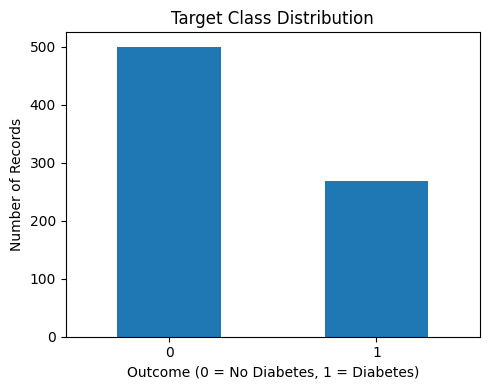

In [7]:
plt.figure(figsize=(5, 4))
df['Outcome'].value_counts().sort_index().plot(kind='bar')
plt.title('Target Class Distribution')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

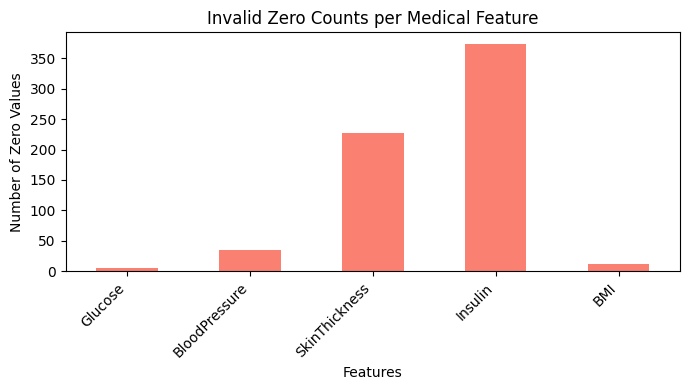

In [8]:
plt.figure(figsize=(7, 4))
zero_counts['Invalid zero count'].plot(kind='bar', color='salmon')
plt.title('Invalid Zero Counts per Medical Feature')
plt.xlabel('Features')
plt.ylabel('Number of Zero Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##5. Replace invalid zeros with missing values

The zero values are converted to NaN. Median imputation is performed later inside the preprocessing pipeline, using training data only.

The missing values are now isolated as NaN so they can be accurately filled using the median values derived exclusively from the training set.

In [9]:
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

print('Missing values after replacing invalid zeros:')
display(df_clean.isnull().sum().to_frame('Missing values'))

Missing values after replacing invalid zeros:


,Missing values
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


## 6. Separate features and target, then split the data

In [10]:
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training set:', X_train.shape)
print('Testing set :', X_test.shape)

Training set: (614, 8)
Testing set : (154, 8)


In [11]:
# Prints the percentage proportion of each class in the training split
print('\nTraining set class distribution:')
print(y_train.value_counts(normalize=True) * 100)

 # Prints the percentage proportion of each class in the testing split
print('\nTesting set class distribution:')
print(y_test.value_counts(normalize=True) * 100)


Training set class distribution:
Outcome
0    65.14658
1    34.85342
Name: proportion, dtype: float64

Testing set class distribution:
Outcome
0    64.935065
1    35.064935
Name: proportion, dtype: float64


## 7. Median imputation + StandardScaler + balanced Logistic Regression
A single scikit-learn pipeline is used so preprocessing is learned only from the training data and data leakage is avoided.

In [12]:
model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic_regression', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print('Balanced Logistic Regression model trained successfully.')

Balanced Logistic Regression model trained successfully.


## 8. Predictions and evaluation metrics

In [13]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Score': [accuracy, precision, recall, f1, roc_auc]
})
metrics_df['Score'] = metrics_df['Score'].round(3)
display(metrics_df)



,Metric,Score
0,Accuracy,0.734
1,Precision,0.603
2,Recall,0.704
3,F1-score,0.650
4,ROC-AUC,0.813


In [14]:
print('\nClassification Report:')
print(classification_report(y_test, y_pred, digits=3, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

           0      0.824     0.750     0.785       100
           1      0.603     0.704     0.650        54

    accuracy                          0.734       154
   macro avg      0.714     0.727     0.717       154
weighted avg      0.747     0.734     0.738       154



## 9. Confusion Matrix

Confusion Matrix:
[[75 25]
 [16 38]]


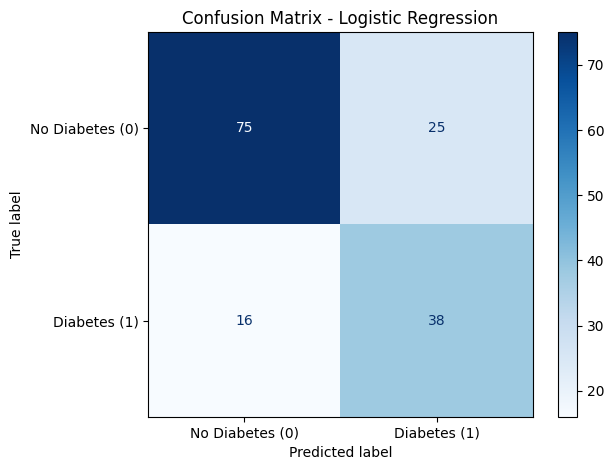

In [15]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes (0)', 'Diabetes (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()

Confusion Matrix:
[[75 25]
 [16 38]]


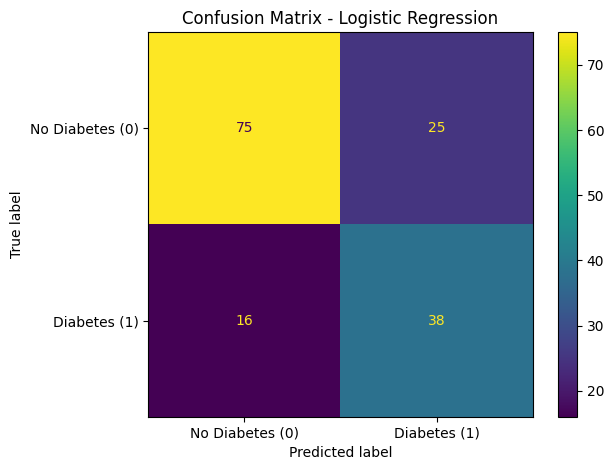

In [16]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes (0)', 'Diabetes (1)'])
disp.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()

## 10. ROC(Receiver Operating Characteristic) Curve

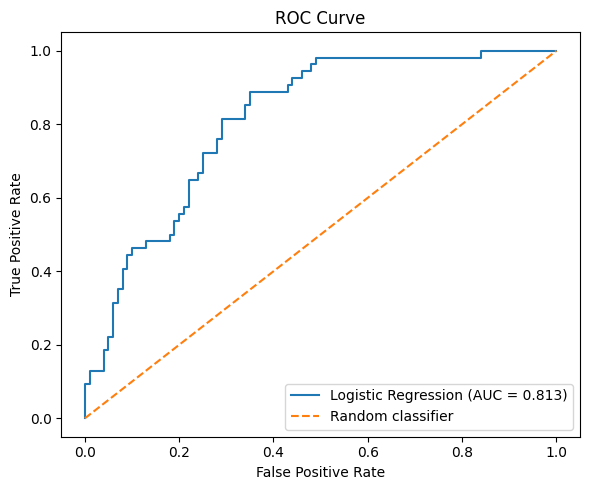

In [17]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()


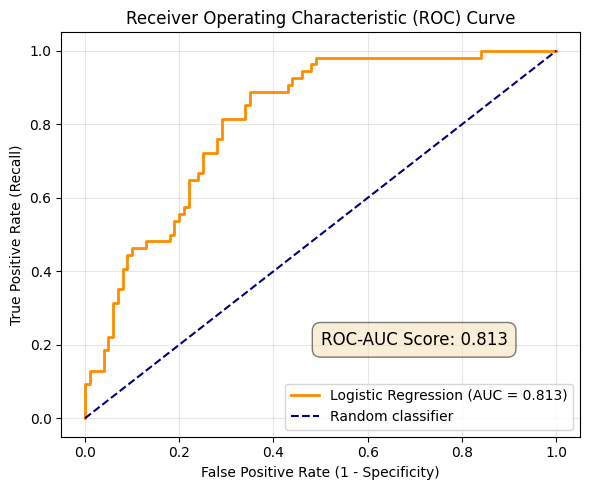

In [18]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.3f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='navy', label='Random classifier')

# Optional extra detail: highlight AUC score inside the plot area
plt.text(0.5, 0.2, f'ROC-AUC Score: {roc_auc:.3f}', fontsize=12,
         bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))

plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Interpret Logistic Regression coefficients
Positive coefficients indicate that higher values of a feature push the prediction toward the diabetes class, while negative coefficients push it in the opposite direction.

In [19]:
coef = model.named_steps['logistic_regression'].coef_[0]
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coef,
    'Absolute coefficient': np.abs(coef)
}).sort_values('Absolute coefficient', ascending=False)

display(coef_df[['Feature', 'Coefficient']].round(4))


,Feature,Coefficient
1,Glucose,1.1835
5,BMI,0.7096
0,Pregnancies,0.3729
6,DiabetesPedigreeFunction,0.2877
7,Age,0.1864
4,Insulin,-0.0446
2,BloodPressure,-0.0146
3,SkinThickness,0.0140


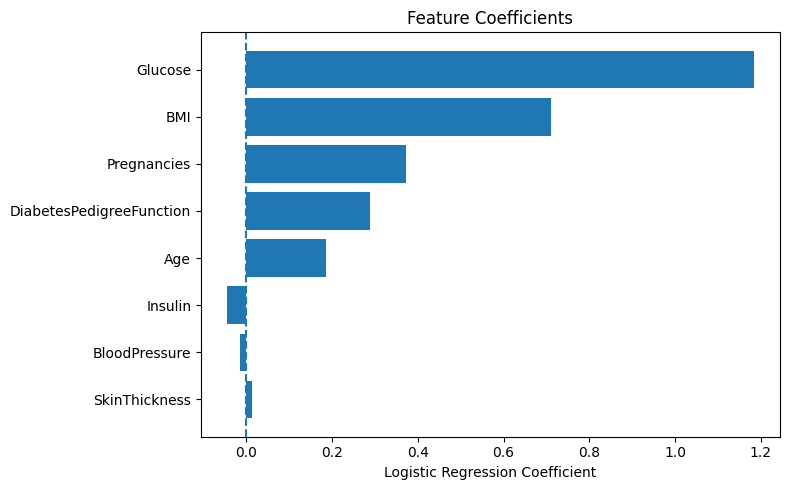

In [20]:
plt.figure(figsize=(8, 5))
plt.barh(coef_df['Feature'], coef_df['Coefficient'])
plt.axvline(0, linestyle='--')
plt.xlabel('Logistic Regression Coefficient')
plt.title('Feature Coefficients')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


<div align="justify">

## 12. Final Conclusion

* **Model Overview & Approach:** The Logistic Regression model provides a baseline binary classification approach for predicting diabetes from the eight required input variables.
* **Clinical Prioritization (Recall):** Recall is especially important for this screening-style task because a false negative represents a positive case that was not detected.
* **Performance Benchmark:** The project evaluation yields a reference ROC-AUC of about 0.813 and a recall of about 0.704.
* **Feature Impact:** **Glucose** and **BMI** are identified as strong positive contributors driving the prediction toward the diabetes class.


</div>